# Dataset #2: NBA Box Scores & Player Game Statistics (Kaggle)

Owner: Joshua. Source: [Kaggle: Historical NBA Data and Player Box Scores](https://www.kaggle.com/datasets/eoinamoore/historical-nba-data-and-player-box-scores). One row per player per game (regular season, playoffs, preseason); we keep 2015 onward.

*Part of the COGS 108 data-cleaning pipeline. See [README.md](README.md) for how the six datasets fit together and the order to run the notebooks in.*

## 2A. Data description & important metrics

This dataset contains historical individual game logs for NBA players spanning regular season, preseason, and playoff games. The observational unit is an individual player's performance within a single scheduled game. Key metrics include:
- **`numMinutes` (Playing Time):** Measured in continuous minutes (e.g., 27.82 minutes). A value of 0 or NaN indicates the player did not enter the game (DNP). Standard regulation games last 48 minutes (overtime adds 5 minutes per period), meaning typical individual playing times range from 5 to 40 minutes.
- **Counting Stats (`points`, `assists`, `reboundsTotal`, `steals`, `blocks`, `turnovers`):** Measured in integer counts per game. For typical rotation players, points range between 5 and 25 per game (rarely exceeding 50), while single-game assists and rebounds typically fall between 0 and 15.
- **Shooting Efficiency (`fieldGoalsPercentage`, `threePointersPercentage`, `freeThrowsPercentage`):** Expressed as decimal proportions bounded between 0.000 and 1.000. These represent shots made divided by shots attempted. A league-average true shooting percentage hovers around 55% to 58%, while elite three-point shooters typically shoot between 37% and 42% over a season.

## 2B. Dataset concerns and limitations

1. **Survivorship & Playing Time Bias:** The sample reflects active roster selections on game nights. Bench players with sporadic playing time exhibit extreme variance in rate stats (e.g., going 1-for-1 from three equates to a 100% shooting percentage over 2 minutes), which can distort model feature weights if minimum minute thresholds are not applied.
2. **Missing Not at Random (MNAR) in Box Scores:** Inactive players (due to injury, load management, or coach decisions) register as NaN for minutes and counting metrics rather than 0. Dropping these rows ensures per-game averages reflect true on-court production, but requires aggregating row counts separately to track player durability (Games Played).
3. **Era Differences and Rule Shifts:** Spanning from 1947 to present, older eras lack tracking metrics (e.g., the three-point line was introduced in 1979; blocks, steals, and turnovers were not tracked prior to 1973). To ensure feature consistency for predictive trade modeling, we restrict our subset to the modern era (2015 onwards).

## Setup

All file paths come from `nba_cleaning_utils.py`, which points at the `data-files/` folder (`RAW` = `00-raw/`, `INTERIM` = `01-interim/`, `PROCESSED` = `02-processed/`).

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nba_cleaning_utils import RAW, INTERIM, PROCESSED

# The Kaggle download contains several files; we only use PlayerStatistics.csv
print(sorted(os.listdir(RAW)))

['.gitkeep', 'NBA Salaries(1990-2023).csv', 'PlayerStatistics.csv', 'bbref_team_salaries_2015_2026.csv', 'hf_cap_tax_aprons.csv', 'hf_min_salaries.csv', 'hf_player_salaries.csv', 'hf_team_payrolls.csv', 'nba_league_leaders_raw.csv', 'nba_player_movement.json']


## 3A. Load the data

In [2]:
df_raw = pd.read_csv(RAW / 'PlayerStatistics.csv',low_memory=False)
df_raw

,firstName,lastName,personId,gameId,gameDateTimeEst,playerteamCity,playerteamName,opponentteamCity,opponentteamName,gameType,...,reboundsOffensive,reboundsTotal,foulsPersonal,turnovers,plusMinusPoints,playerteamId,opponentteamId,comment,startingPosition,gameDate
0,Donovan,Clingan,1642270.0,22600032,2026-11-06 22:00:00,Portland,Trail Blazers,Los Angeles,Lakers,Regular Season,...,2.0,11.0,5.0,3.0,-7.0,1.610613e+09,1.610613e+09,NaN,C,2026-11-06 22:00:00
1,Jarred,Vanderbilt,1629020.0,22600032,2026-11-06 22:00:00,Los Angeles,Lakers,Portland,Trail Blazers,Regular Season,...,0.0,0.0,0.0,0.0,0.0,1.610613e+09,1.610613e+09,DNP - Coach's Decision,NaN,2026-11-06 22:00:00
2,Sidy,Cissoko,1631321.0,22600032,2026-11-06 22:00:00,Portland,Trail Blazers,Los Angeles,Lakers,Regular Season,...,1.0,2.0,3.0,0.0,-13.0,1.610613e+09,1.610613e+09,NaN,NaN,2026-11-06 22:00:00
3,Scoot,Henderson,1630703.0,22600032,2026-11-06 22:00:00,Portland,Trail Blazers,Los Angeles,Lakers,Regular Season,...,0.0,2.0,5.0,5.0,-2.0,1.610613e+09,1.610613e+09,NaN,G,2026-11-06 22:00:00
4,Robert,Williams III,1629057.0,22600032,2026-11-06 22:00:00,Portland,Trail Blazers,Los Angeles,Lakers,Regular Season,...,3.0,5.0,2.0,1.0,1.0,1.610613e+09,1.610613e+09,NaN,NaN,2026-11-06 22:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1676586,Nelson,Weidemann,196295088.0,12400060,NaN,Ratiopharm,NaN,NaN,NaN,Pre Season,...,0.0,1.0,4.0,1.0,-16.0,NaN,NaN,NaN,NaN,NaN
1676587,Donovan,Clingan,1642270.0,12400060,NaN,Portland,NaN,NaN,NaN,Pre Season,...,5.0,11.0,2.0,1.0,-8.0,NaN,NaN,NaN,NaN,NaN
1676588,Tobias,Jensen,196295090.0,12400060,NaN,Ratiopharm,NaN,NaN,NaN,Pre Season,...,0.0,0.0,0.0,1.0,-2.0,NaN,NaN,NaN,NaN,NaN
1676589,Thomas,Klepeisz,196295098.0,12400060,NaN,Ratiopharm,NaN,NaN,NaN,Pre Season,...,0.0,1.0,2.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [3]:
#I got an error message saying columns (10,11,12) have mixed types.
#These columns are object type
errorcols = df_raw[df_raw.columns[[10,11,12]]]
errorcols

,gameLabel,gameSubLabel,seriesGameNumber
0,Emirates NBA Cup,West Group C,NaN
1,Emirates NBA Cup,West Group C,NaN
2,Emirates NBA Cup,West Group C,NaN
3,Emirates NBA Cup,West Group C,NaN
4,Emirates NBA Cup,West Group C,NaN
...,...,...,...
1676586,NaN,NaN,NaN
1676587,NaN,NaN,NaN
1676588,NaN,NaN,NaN
1676589,NaN,NaN,NaN


## 3B. Is the data tidy?

We can see the data is NOT clean OR Tidy as seen with the error cols, and in 3A we can see redundant columns like 'opponentTeam', 'opponentTeamCity', or 'GameDateTimeEst' which we dont really need at all to determin player values

In [4]:
#filtering out only the neccesary columns for Player value
df_neccesary = df_raw[['firstName', 'lastName', 'personId','gameDate', 'playerteamName','gameType', 'numMinutes', 'points', 'assists',
       'blocks', 'steals','fieldGoalsPercentage','threePointersPercentage','freeThrowsPercentage','reboundsTotal','turnovers']]
df_neccesary

,firstName,lastName,personId,gameDate,playerteamName,gameType,numMinutes,points,assists,blocks,steals,fieldGoalsPercentage,threePointersPercentage,freeThrowsPercentage,reboundsTotal,turnovers
0,Donovan,Clingan,1642270.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,27.816666666666666,17.0,1.0,2.0,1.0,0.750,0.6,0.667,11.0,3.0
1,Jarred,Vanderbilt,1629020.0,2026-11-06 22:00:00,Lakers,Regular Season,NaN,0.0,0.0,0.0,0.0,0.000,0.0,0.000,0.0,0.0
2,Sidy,Cissoko,1631321.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,22.016666666666666,7.0,3.0,1.0,0.0,0.286,0.4,0.500,2.0,0.0
3,Scoot,Henderson,1630703.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,22.916666666666668,2.0,0.0,0.0,0.0,0.000,0.0,0.500,2.0,5.0
4,Robert,Williams III,1629057.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,16.466666666666665,9.0,2.0,2.0,2.0,0.800,0.0,1.000,5.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1676586,Nelson,Weidemann,196295088.0,NaN,NaN,Pre Season,15:07,7.0,1.0,0.0,1.0,0.400,1.0,1.000,1.0,1.0
1676587,Donovan,Clingan,1642270.0,NaN,NaN,Pre Season,20:30,4.0,0.0,1.0,0.0,0.286,0.0,0.000,11.0,1.0
1676588,Tobias,Jensen,196295090.0,NaN,NaN,Pre Season,13:25,5.0,0.0,0.0,0.0,0.667,0.5,0.000,0.0,1.0
1676589,Thomas,Klepeisz,196295098.0,NaN,NaN,Pre Season,15:35,9.0,4.0,0.0,1.0,0.429,0.5,0.000,1.0,0.0


## 3C. Size of the data

In [5]:
#raw size, showing the stats of each player for EVER GAME since 1947
df_neccesary.shape

(1676591, 16)

## 3D. Missing data

In [6]:
#checking the amount of NaN values in filterd dataframe
df_neccesary.isna().sum()
#there is alot of missing values in numMinutes, thats because in the filtered out 'comments'

firstName                     234
lastName                      238
personId                       45
gameDate                     3513
playerteamName               3513
gameType                       50
numMinutes                 170545
points                       1687
assists                      1687
blocks                       1687
steals                       1687
fieldGoalsPercentage         1687
threePointersPercentage      1687
freeThrowsPercentage         1687
reboundsTotal                1687
turnovers                    1687
dtype: int64

In [7]:
#there is alot of missing values in numMinutes, thats because in the filtered out 'comment' column gave an explanation for why there was the player wasnt playing
#and if a play was playing 'comment' would be NaN
df_raw[['numMinutes','comment']]

,numMinutes,comment
0,27.816666666666666,NaN
1,NaN,DNP - Coach's Decision
2,22.016666666666666,NaN
3,22.916666666666668,NaN
4,16.466666666666665,NaN
...,...,...
1676586,15:07,NaN
1676587,20:30,NaN
1676588,13:25,NaN
1676589,15:35,NaN


## 3F. Clean the data

*(Cleaning comes before the outlier check for this dataset, because the summary statistics in 3E only make sense once the did-not-play rows are removed.)*

**Wrangling, tidiness, and missingness justification**
- **Tidiness:** The dataset follows tidy data principles where each row represents a single observational unit (one player in one game) and each column records a distinct attribute (player identity, game date, team, and box-score statistics). First and last names were concatenated into a unified `player` variable to simplify joining with contract and trade datasets.
- **Handling Missing Values:**
  - **Metadata NaNs:** Dropped observations missing `gameDate`, `playerteamName`, or `gameType`, as unanchored games cannot be assigned to an NBA season or competition context.
  - **Did Not Play (DNP) Records:** Filtered to rows with `numMinutes > 0`, removing 119,152 unplayed bench appearances. Dropping DNP rows prevents downward bias on per-game scoring averages, while season durability is preserved through total game appearance counts.

**Step 0: make `numMinutes` numeric**

The current Kaggle download (1.68M rows, more than the 677K-row version this section was first written for) stores `numMinutes` as text, and some very old box scores write it as `"MM:SS"`. We convert it to decimal minutes so the `numMinutes > 0` filter below works. Every `"MM:SS"` row also has no `gameDate`, so those rows are dropped in Step 1 either way.

In [8]:
mins = df_neccesary['numMinutes'].astype('string')
mmss = mins.str.extract(r'^(\d+):(\d+)$').astype(float)
print('rows with minutes written as MM:SS:', mmss[0].notna().sum(),
      '| of those, rows with a gameDate:', (mmss[0].notna() & df_neccesary['gameDate'].notna()).sum())

df_neccesary = df_neccesary.assign(
    numMinutes=pd.to_numeric(mins, errors='coerce').fillna(mmss[0] + mmss[1] / 60).astype(float))
df_neccesary['numMinutes'].dtype

rows with minutes written as MM:SS: 2097 | of those, rows with a gameDate: 0


dtype('float64')

**Step 1: drop rows with missing metadata and did-not-play rows**

In [9]:
#cleaning the NaN values, dropping any rows that have NaN in non-negotiable columns
df_clean = df_neccesary.dropna(subset=['gameDate', 'playerteamName', 'gameType']).copy()
#cleaning the Nan values in Core statistics
df_clean = df_clean.dropna(subset=['points','assists','reboundsTotal','steals','blocks','turnovers'],how='all')
#filtering out Not played games
df_clean = df_clean[df_clean['numMinutes']>0]
#checking if there is any NaN values left
df_clean.isna().sum()

firstName                  0
lastName                   0
personId                   0
gameDate                   0
playerteamName             0
gameType                   0
numMinutes                 0
points                     0
assists                    0
blocks                     0
steals                     0
fieldGoalsPercentage       0
threePointersPercentage    0
freeThrowsPercentage       0
reboundsTotal              0
turnovers                  0
dtype: int64

**Step 2: finish tidying (one `player` column, a `season` column) and keep 2015 onward**

In [10]:
#now we tidy the data to get rid of redundant columns
final_df = df_clean.copy()
#combining first and last name columns
final_df['player'] = final_df["firstName"].str.strip() + " " + final_df["lastName"].str.strip()
final_df = final_df.drop(columns =["firstName", "lastName"])
#converting gameDate to seasonal
final_df['gameDate'] = pd.to_datetime(final_df['gameDate'])
#any game in the month >= october is technically counted as a new season
final_df['season'] = np.where(final_df["gameDate"].dt.month >= 10,
    final_df["gameDate"].dt.year + 1,
    final_df["gameDate"].dt.year,
)
#grabbing data from 2015 and after (final step)
final_df = final_df[final_df['season'] >= 2015]
final_df

,personId,gameDate,playerteamName,gameType,numMinutes,points,assists,blocks,steals,fieldGoalsPercentage,threePointersPercentage,freeThrowsPercentage,reboundsTotal,turnovers,player,season
0,1642270.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,27.816667,17.0,1.0,2.0,1.0,0.750,0.600,0.667,11.0,3.0,Donovan Clingan,2027
2,1631321.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,22.016667,7.0,3.0,1.0,0.0,0.286,0.400,0.500,2.0,0.0,Sidy Cissoko,2027
3,1630703.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,22.916667,2.0,0.0,0.0,0.0,0.000,0.000,0.500,2.0,5.0,Scoot Henderson,2027
4,1629057.0,2026-11-06 22:00:00,Trail Blazers,Regular Season,16.466667,9.0,2.0,2.0,2.0,0.800,0.000,1.000,5.0,1.0,Robert Williams III,2027
5,1630572.0,2026-11-06 22:00:00,Lakers,Regular Season,20.116667,7.0,1.0,1.0,1.0,0.333,0.333,1.000,3.0,0.0,Sandro Mamukelashvili,2027
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
440462,203893.0,2014-10-04 19:30:00,Pelicans,Preseason,13.000000,12.0,1.0,0.0,2.0,0.571,1.000,0.750,3.0,2.0,Russ Smith,2015
440463,101122.0,2014-10-04 19:30:00,Heat,Preseason,22.000000,12.0,4.0,0.0,0.0,0.625,0.500,0.000,2.0,1.0,Danny Granger,2015
440464,201600.0,2014-10-04 19:30:00,Pelicans,Preseason,6.000000,2.0,1.0,1.0,0.0,0.500,0.000,0.000,3.0,1.0,Omer Asik,2015
440465,202690.0,2014-10-04 19:30:00,Pelicans,Preseason,30.000000,17.0,3.0,0.0,2.0,0.667,0.750,1.000,1.0,2.0,Jimmer Fredette,2015


## 3E. Outliers and extreme values

In [11]:
#finding the statitics for each core metric of a player
final_df[['numMinutes', 'points', 'reboundsTotal', 'assists', 'turnovers', 'steals', 'blocks']].describe()

,numMinutes,points,reboundsTotal,assists,turnovers,steals,blocks
count,355430.000000,355430.000000,355430.000000,355430.000000,355430.000000,355430.000000,355430.000000
mean,22.058180,10.200526,4.096759,2.267712,1.271491,0.726211,0.452911
std,10.488139,8.377496,3.428526,2.514029,1.392119,0.962997,0.823617
min,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,14.390000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000
50%,23.000000,8.000000,3.000000,2.000000,1.000000,0.000000,0.000000
75%,30.110000,15.000000,6.000000,3.000000,2.000000,1.000000,1.000000
max,64.000000,83.000000,31.000000,25.000000,12.000000,10.000000,12.000000


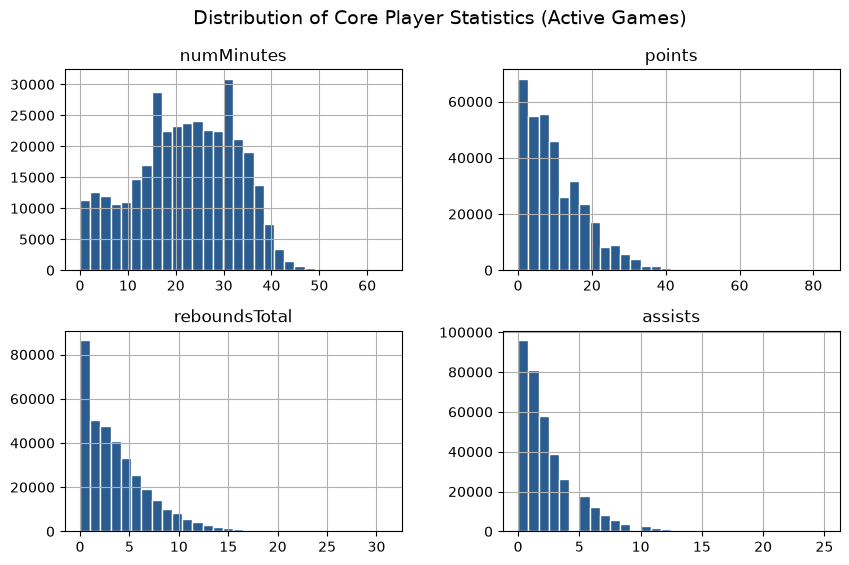

In [12]:
#visualizing cleaned data
final_df[['numMinutes', 'points', 'reboundsTotal', 'assists']].hist(
    figsize=(10, 6), 
    bins=30, 
    color='#2b5c8f', 
    edgecolor='white'
)
plt.suptitle("Distribution of Core Player Statistics (Active Games)", fontsize=14)
plt.show()

**Summary statistics & distribution findings (3E & 4)**

The descriptive statistics table generated from `final_df[stats_cols].describe()` evaluates 355,430 active player-game observations from the modern era (2015–present), confirming data cleanliness, characteristic right-skewed distributions, and realistic NBA domain boundaries:

* **Complete Dimensional Integrity ($N = 355,430$):** Every metric records an identical count of 355,430 observations, verifying that the cleaning pipeline successfully resolved all missingness without leaving orphan `NaN` values in the analytical columns.
* **Playing Time Bounds (`numMinutes`):** Minutes played average 22.06 minutes with a median of 23.00 minutes and an interquartile range (IQR) spanning 14.39 to 30.11 minutes, which closely reflects standard NBA rotation allocations between reserve contributors and primary starters. The minimum of 0.01 minutes (~0.6 seconds) represents late-clock situational substitutions or immediate injury exits, while the maximum of 64.00 minutes reflects multi-overtime games (a regulation 48-minute contest extended by multiple 5-minute overtime periods), confirming all durations fall strictly within physically possible limits.
* **Positive Skewness Across Counting Statistics:** Across all core production categories, the mean consistently exceeds the median (`points`: 10.20 mean vs. 8.00 median; `reboundsTotal`: 4.10 mean vs. 3.00 median; `assists`: 2.27 mean vs. 2.00 median). This positive (right) skew aligns with NBA tactical structures, where the majority of rostered players produce modest single-digit contributions while high-usage offensive focal points generate high-volume stat lines in the upper tail.
* **Discrete Specialist Metrics (`steals`, `blocks`, `turnovers`):** For both steals and blocks, the 25th and 50th percentiles are 0.0, indicating that over half of active player appearances record zero defensive disruptions. The 75th percentiles (1.0 steal, 1.0 block) and means (0.73 steals, 0.45 blocks) demonstrate that defensive events are relatively rare per-game occurrences.
* **Verification of Extreme Outliers:**
  * **Scoring (`points` max: 83.0):** The extreme maximum points and upper percentile values match high-scoring record breaking game of Bam Adebayo against the Washington Wizards. https://www.youtube.com/watch?v=FE1rL7xzsR8
  * **Playmaking & Rebounding (`assists` max: 25.0, `reboundsTotal` max: 31.0):** The upper bounds align directly with verified modern single-game historical records (such as Rajon Rondo's 25-assist game in 2017 and Jusuf Nurkić's 31-rebound game in 2024).
  * **Defensive Extremes (`steals` max: 10.0, `blocks` max: 12.0):** Peak figures reflect historic individual defensive performances (such as Lou Williams and Draymond Green recording 10-steal games, and Hassan Whiteside recording 12-block games in the modern tracking window).

Because all minimum values satisfy non-negativity constraints ($\ge 0$) and all maximums represent legitimate historical peaks rather than sensor or transcription artifacts, these extreme values are retained without trimming so downstream models can capture true elite production ceilings.

## 3G. Save the cleaned data

In [13]:
#writing back to data-files/02-processed
# The current raw file has a few blank personIds (all dropped above), which made pandas read the
# column as float. Store it as a whole number so it joins cleanly with the other NBA-id datasets.
final_df['personId'] = final_df['personId'].astype('int64')
os.makedirs(PROCESSED, exist_ok=True)
final_df.to_csv(PROCESSED / "player_game_stats_cleaned.csv", index=False)